In [ ]:
import csv
import random
from collections import defaultdict
from pathlib import Path

import os
import cv2
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from datasets import load_dataset
from PIL import Image
from tqdm.auto import tqdm

In [24]:
OUTPUT_DIR = Path("../../data/application/cal_tech_101/raw")
PREPROCESS_DIR = OUTPUT_DIR.parent / "pre_process"
PATCHES_DIR = PREPROCESS_DIR / "patches"

spmf_path = PREPROCESS_DIR / "transactions.txt"
img_map_path = PREPROCESS_DIR / "image_mapping.csv"
word_stats_path = PREPROCESS_DIR / "visual_word_stats.csv"

TARGET_CLASSES = ["airplanes", "motorbikes", "faces_easy"]
SAMPLES_PER_CLASS = 200  
SEED = 0

MAX_IMG_SIDE = 300       
MAX_SIFT_FEATURES = 60  
K_CLUSTERS = 300        
PATCH_SIZE = 48          
TOP_K_PATCHES = 9

random.seed(SEED)
np.random.seed(SEED)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PREPROCESS_DIR.mkdir(parents=True, exist_ok=True)
PATCHES_DIR.mkdir(parents=True, exist_ok=True)

In [13]:
def download_caltech101_subset(
    output_dir: Path,
    target_classes: list[str],
    samples_per_class: int,
    seed: int,
    force: bool = False,
) -> pd.DataFrame:
    
    meta_path = output_dir / "metadata.csv"
    images_dir = output_dir / "images"
    
    if meta_path.exists() and not force:
        df_existing = pd.read_csv(meta_path)
        expected = len(target_classes) * samples_per_class
        
        if len(df_existing) == expected and set(df_existing["class_name"]) == set(c.lower() for c in target_classes):
            print(f"Đầy đủ file. Không cần tải {output_dir}")
            return df_existing
        
    images_dir.mkdir(parents=True, exist_ok=True)
    
    dataset = load_dataset("flwrlabs/caltech101", split="train")
    label_names = dataset.features["label"].names
    
    name_to_id = {name.lower(): idx for idx, name in enumerate(label_names)}
    
    missing = [c for c in target_classes if c.lower() not in name_to_id]
    if missing:
        raise ValueError(f"Không tìm thấy lớp: {missing}. Danh sách hợp lệ: {label_names}")
            
    all_labels = dataset["label"]
    rng = random.Random(seed)
    
    rows = []
    
    for cls_name in target_classes:
        cls_key = cls_name.lower()
        lid = name_to_id[cls_key]
        
        cls_indices = [i for i, lbl in enumerate(all_labels) if lbl == lid]
        rng.shuffle(cls_indices)
        chosen_indices = cls_indices[:samples_per_class]
        
        cls_dir = images_dir / cls_key
        cls_dir.mkdir(parents=True, exist_ok=True)
        
        for local_idx, ds_idx in enumerate(tqdm(chosen_indices, desc=f"Downloading {cls_key}")):
            img = dataset[ds_idx]["image"].convert("RGB")
            w, h = img.size
            filename = f"{cls_key}_{local_idx:03d}.jpg"
            save_path = cls_dir / filename
            img.save(save_path, format="JPEG", quality=95)

            rows.append({
                "image_id": f"{cls_key}_{local_idx:03d}",
                "class_name": cls_key,
                "orig_ds_index": ds_idx,
                "rel_path": f"images/{cls_key}/{filename}",
                "width": w,
                "height": h,
            })

    df_meta = pd.DataFrame(rows)
    df_meta.to_csv(meta_path, index=False, encoding="utf-8")
    print(f"Hoàn tất! Đã lưu {len(df_meta)} ảnh và metadata tại {meta_path}")
    return df_meta

In [14]:
df_meta = download_caltech101_subset(
    output_dir=OUTPUT_DIR,
    target_classes=TARGET_CLASSES,
    samples_per_class=SAMPLES_PER_CLASS,
    seed=SEED,
)
df_meta.groupby("class_name").size()

Hoàn tất! Đã lưu 600 ảnh và metadata tại ..\..\data\application\cal_tech_101\raw\metadata.csv


class_name
airplanes     200
faces_easy    200
motorbikes    200
dtype: int64

In [15]:
# Đọc ảnh bằng PI và resize cạnh dài nhất về max_side.
def load_and_resize_rgb(img_path:Path, max_side: int = MAX_IMG_SIDE) -> np.ndarray:
    with Image.open(img_path) as pil_img:
        rgb = np.array(pil_img.convert("RGB"))
    
    # (height, width, channels)
    h, w = rgb.shape[:2]
    scale = max_side / max(h, w)
    
    if scale != 1:
        new_w, new_h = max(1, int(round(w * scale))), max(1, int(round(h * scale)))
        interp = cv2.INTER_AREA if scale < 1.0 else cv2.INTER_LINEAR
        rgb = cv2.resize(rgb, (new_w, new_h), interpolation=interp)
    
    return rgb

# Chuyển SIFT chuẩn sang RootSIFT (L1-norm rồi lấy căn bậc hai)
def to_rootsift(descriptors: np.ndarray, eps: float = 1e-7)->np.ndarray:
    des = descriptors.astype(np.float32)
    
    des /= (des.sum(axis=1, keepdims=True) + eps)
    return np.sqrt(des)

In [17]:
sift = cv2.SIFT_create(nfeatures = MAX_SIFT_FEATURES)

all_descriptors = []
kp_records = [] # (img_idx, x, y, kp_size)
img_kp_counts = []

for img_idx, row in tqdm(df_meta.iterrows(), total=len(df_meta), desc = "Extracting RootSIFT"):
    img_path = OUTPUT_DIR / row["rel_path"]
    
    rgb = load_and_resize_rgb(img_path, max_side=MAX_IMG_SIDE)
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    
    kps, des = sift.detectAndCompute(gray, None)
    if des is None or len(kps) == 0:
        img_kp_counts.append(0)
        continue
    
    if len(kps) > MAX_SIFT_FEATURES:
        order = np.argsort([-kp.response for kp in kps])[:MAX_SIFT_FEATURES]
        kps = [kps[i] for i in order]
        des = des[order]
        
    des_root = to_rootsift(des)

    all_descriptors.append(des_root)
    img_kp_counts.append(len(kps))
    
    for kp in kps:
        kp_records.append((img_idx, float(kp.pt[0]), float(kp.pt[1]), float(kp.size)))

X_des = np.vstack(all_descriptors).astype(np.float32)
kp_img_idx = np.array([r[0] for r in kp_records], dtype=np.int32)

print(f"Tổng số descriptor trích được: {X_des.shape[0]:,} (dim={X_des.shape[1]})")
print(f"Số keypoint trung bình/ảnh   : {np.mean(img_kp_counts):.1f} (min={np.min(img_kp_counts)}, max={np.max(img_kp_counts)})")
print(f"Số ảnh bị rỗng keypoint      : {sum(c == 0 for c in img_kp_counts)}")

Extracting RootSIFT:   0%|          | 0/600 [00:00<?, ?it/s]

Extracting RootSIFT: 100%|██████████| 600/600 [00:10<00:00, 56.65it/s]

Tổng số descriptor trích được: 35,968 (dim=128)
Số keypoint trung bình/ảnh   : 59.9 (min=49, max=60)
Số ảnh bị rỗng keypoint      : 0


In [ ]:
from sklearn.cluster import MiniBatchKMeans
from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=K_CLUSTERS,
    random_state=SEED,
    n_init=10,
) 

cluster_labels = kmeans.fit_predict(X_des)
word_ids = cluster_labels + 1

codebook_path = PREPROCESS_DIR / "codebook_kmeans.joblib"
joblib.dump(kmeans, codebook_path)

unique_used = len(np.unique(word_ids))

KMeans với K=300, số visual word thực dùng: 300/300
Inertia: 6,460.88 | Đã lưu codebook tại: ..\..\data\application\cal_tech_101\pre_process\codebook_kmeans.joblib


In [ ]:
print(f"KMeans với K={K_CLUSTERS}, số visual word thực dùng: {unique_used}/{K_CLUSTERS}")
print(f"Inertia: {kmeans.inertia_:,.2f} | Đã lưu codebook tại: \n{codebook_path.resolve()}")

KMeans với K=300, số visual word thực dùng: 300/300
Inertia: 6,460.88 | Đã lưu codebook tại: 
D:\US\Data mining\group_proj\Group_12_Charm\data\application\cal_tech_101\pre_process\codebook_kmeans.joblib
[ 27  14 268 ... 254 243 119]


In [ ]:
img_to_words = defaultdict(set)
# Gom các Visual Word về đúng bức ảnh của nó
for img_idx, wid in zip(kp_img_idx, word_ids):
    img_to_words[int(img_idx)].add(int(wid))


tx_rows = [] # transaction.txt
mapping_rows = [] 
word_doc_freq = defaultdict(int)
word_class_freq = defaultdict(lambda: defaultdict(int))

tid_counter = 0

for img_idx, row in df_meta.iterrows():
    words_sorted = sorted(img_to_words.get(img_idx, set()))
    if not words_sorted:
        print(f"[WARN] Ảnh rỗng keypoint: {row['image_id']}")
        continue
    
    tid_counter += 1
    tx_rows.append(" ".join(map(str, words_sorted)))
    
    cls = row["class_name"]
    for w in words_sorted:
        word_doc_freq[w] += 1
        word_class_freq[w][cls] += 1
        
    mapping_rows.append({
        "tid": tid_counter,              # Khớp dòng thứ tid (1-based) trong transactions.txt
        "image_id": row["image_id"],
        "class_name": cls,
        "rel_path": row["rel_path"],
        "num_keypoints": img_kp_counts[img_idx],
        "tx_length": len(words_sorted),
    })

# Ghi file SPMF
with open(spmf_path, "w", encoding="utf-8") as f:
    f.write("\n".join(tx_rows) + "\n")
    
# Map tid -> img -> class
df_img_map = pd.DataFrame(mapping_rows)
df_img_map.to_csv(img_map_path, index=False, encoding="utf-8")

# Thống kê visual word
word_total_kps = np.bincount(word_ids, minlength=K_CLUSTERS + 1)
n_tx = len(df_img_map)

word_stats_rows = []
for w in range(1, K_CLUSTERS + 1):
    
    df_w = word_doc_freq[w]
    cls_counts = word_class_freq[w]
    
    if df_w > 0:
        top_cls = max(cls_counts, key=cls_counts.get)
        top_ratio = cls_counts[top_cls] / df_w
    else:
        top_cls, top_ratio = "none", 0.0
        
    word_stats_rows.append({
        "word_id": w,
        "doc_freq": df_w,
        "support": round(df_w / n_tx, 4),
        "total_keypoints": int(word_total_kps[w]),
        "airplanes_cnt": cls_counts.get("airplanes", 0),
        "motorbikes_cnt": cls_counts.get("motorbikes", 0),
        "faces_easy_cnt": cls_counts.get("faces_easy", 0),
        "top_class": top_cls,
        "top_class_purity": round(top_ratio, 4),
        "patch_file": f"patches/word_{w:03d}.png",
    })
    
df_word_stats = pd.DataFrame(word_stats_rows)
df_word_stats.to_csv(word_stats_path, index=False, encoding="utf-8")

print(f"Đã xuất {n_tx} giao dịch SPMF -> {spmf_path}")
print(f"Đã xuất bảng ánh xạ ảnh      -> {img_map_path}")
print(f"Đã xuất thống kê visual word -> {word_stats_path}")

Đã xuất 600 giao dịch SPMF -> ..\..\data\application\cal_tech_101\pre_process\transactions.txt
Đã xuất bảng ánh xạ ảnh      -> ..\..\data\application\cal_tech_101\pre_process\image_mapping.csv
Đã xuất thống kê visual word -> ..\..\data\application\cal_tech_101\pre_process\visual_word_stats.csv

5 dòng đầu của transactions.txt (cắt gọn 12 item đầu):
  10 14 16 23 25 27 29 30 35 40 43 70 ...
  1 7 9 14 31 33 34 64 70 72 80 83 ...
  2 7 12 17 22 29 31 50 53 59 60 61 ...
  3 9 11 18 27 28 29 33 37 52 83 85 ...
  4 10 16 32 33 34 40 48 52 54 55 63 ...


In [26]:
centers = kmeans.cluster_centers_
word_to_top_des_indices = {}
needed_images = defaultdict(list)

for w in range(1, K_CLUSTERS + 1):
    c_idx = w - 1
    member_idxs = np.where(cluster_labels == c_idx)[0]
    if len(member_idxs) == 0:
        continue
    
    # Khoảng cách Euclid
    dists = np.linalg.norm(X_des[member_idxs] - centers[c_idx], axis=1)
    top_local = np.argsort(dists)[:TOP_K_PATCHES]
    top_global = member_idxs[top_local]
    
    # Tra kp record để lấy lại (img_idx, x, y, kp_size)
    for slot_idx, g_idx in enumerate(top_global):
        img_idx, x, y, kp_size = kp_records[g_idx]
        needed_images[img_idx].append((w, slot_idx, x, y, kp_size))
        
word_patches = defaultdict(dict)
for img_idx, reqs in tqdm(needed_images.items(), desc="Cropping representative patches"):
    img_path = OUTPUT_DIR / df_meta.loc[img_idx, "rel_path"]
    rgb = load_and_resize_rgb(img_path, max_side=MAX_IMG_SIDE)

    for w, slot_idx, x, y, kp_size in reqs:
        # Bán kính vùng cắt tỉ lệ theo đường kính keypoint, chặn trong [16, 48] px
        r = int(np.clip(round(kp_size * 1.5), 16, 48))
        padded = cv2.copyMakeBorder(rgb, r, r, r, r, cv2.BORDER_REFLECT_101)
        cx, cy = int(round(x)) + r, int(round(y)) + r
        crop = padded[cy - r : cy + r, cx - r : cx + r]
        patch = cv2.resize(crop, (PATCH_SIZE, PATCH_SIZE), interpolation=cv2.INTER_AREA)
        word_patches[w][slot_idx] = patch
        
# Ghép thành ảnh lưới 3x3 cho từng visual word và lưu vào patches/
grid_n = int(np.ceil(np.sqrt(TOP_K_PATCHES)))
border = 2
tile_span = PATCH_SIZE + border
canvas_size = grid_n * tile_span + border

saved_count = 0
for w in range(1, K_CLUSTERS + 1):
    canvas = np.full((canvas_size, canvas_size, 3), 240, dtype=np.uint8)
    slots = word_patches.get(w, {})
    for slot_idx in range(TOP_K_PATCHES):
        if slot_idx not in slots:
            continue
        row_i, col_i = divmod(slot_idx, grid_n)
        y0 = border + row_i * tile_span
        x0 = border + col_i * tile_span
        canvas[y0 : y0 + PATCH_SIZE, x0 : x0 + PATCH_SIZE] = slots[slot_idx]

    out_path = PATCHES_DIR / f"word_{w:03d}.png"
    Image.fromarray(canvas).save(out_path)
    saved_count += 1

print(f"Đã lưu {saved_count} ảnh patch đại diện (lưới {grid_n}x{grid_n}) tại: {PATCHES_DIR}")

Cropping representative patches: 100%|██████████| 587/587 [00:01<00:00, 562.57it/s]


Đã lưu 300 ảnh patch đại diện (lưới 3x3) tại: ..\..\data\application\cal_tech_101\pre_process\patches


=== THỐNG KÊ TẬP GIAO DỊCH SPMF (CALTECH-101) ===
Số giao dịch (|D|)      : 600
Số items (|I|)          : 300
Độ dài trung bình       : 47.92 ± 4.52
Độ dài min / median /max: 28 / 48 / 57
Mật độ ma trận          : 15.97%

Độ dài giao dịch trung bình theo từng lớp:
            count    mean  min  max
class_name                         
airplanes     200  46.940   33   57
faces_easy    200  48.655   28   56
motorbikes    200  48.170   36   57


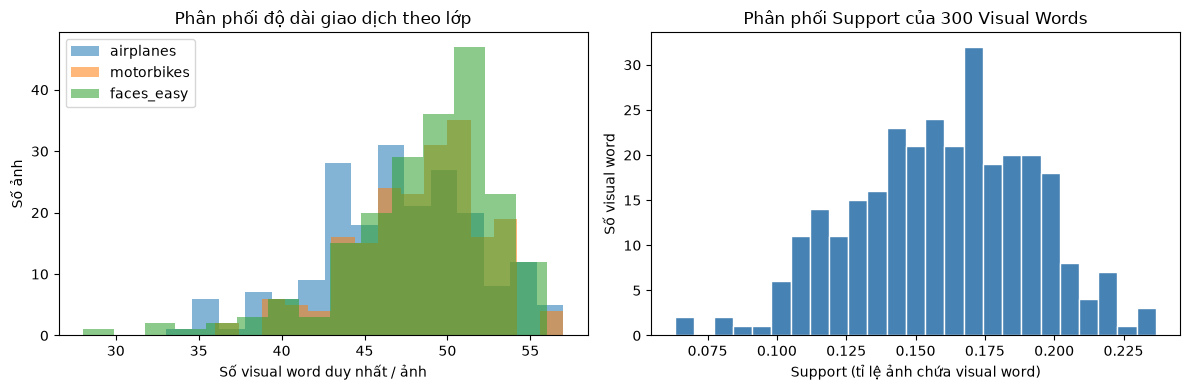

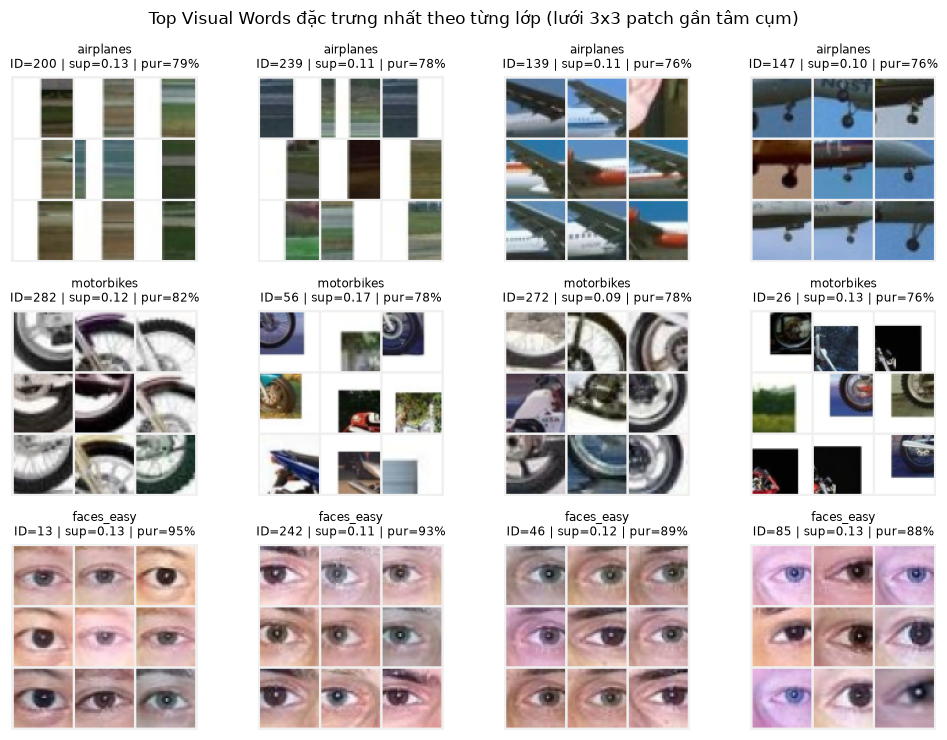

In [ ]:
# Thống kê tổng quan để chọn khoảng minsup cho CHARM
lengths = df_img_map["tx_length"]
density = lengths.mean() / K_CLUSTERS

print("=== THỐNG KÊ TẬP GIAO DỊCH SPMF (CALTECH-101) ===")
print(f"Số giao dịch (|D|)      : {len(df_img_map)}")
print(f"Số items (|I|)          : {K_CLUSTERS}")
print(f"Độ dài trung bình       : {lengths.mean():.2f} ± {lengths.std():.2f}")
print(f"Độ dài min / median /max: {lengths.min()} / {lengths.median():.0f} / {lengths.max()}")
print(f"Mật độ ma trận          : {density * 100:.2f}%")
print("\nĐộ dài giao dịch trung bình theo từng lớp:")
print(df_img_map.groupby("class_name")["tx_length"].agg(["count", "mean", "min", "max"]))

# Vẽ phân phối độ dài giao dịch & support của từng visual word
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for cls in TARGET_CLASSES:
    sub = df_img_map[df_img_map["class_name"] == cls]["tx_length"]
    axes[0].hist(sub, bins=15, alpha=0.55, label=cls)
axes[0].set_title("Phân phối độ dài giao dịch theo lớp")
axes[0].set_xlabel("Số visual word duy nhất / ảnh")
axes[0].set_ylabel("Số ảnh")
axes[0].legend()

axes[1].hist(df_word_stats["support"], bins=25, color="steelblue", edgecolor="white")
axes[1].set_title("Phân phối Support của 300 Visual Words")
axes[1].set_xlabel("Support (tỉ lệ ảnh chứa visual word)")
axes[1].set_ylabel("Số visual word")
plt.tight_layout()
plt.show()

# Xem thử Top-4 visual word mang tính đặc trưng (purity cao nhất, xuất hiện >= 25 ảnh) của mỗi lớp
fig, axes = plt.subplots(len(TARGET_CLASSES), 4, figsize=(10, 7.5))
fig.suptitle("Top Visual Words đặc trưng nhất theo từng lớp (lưới 3x3 patch gần tâm cụm)", fontsize=12)

for r_idx, cls in enumerate(TARGET_CLASSES):
    top_words = (
        df_word_stats[(df_word_stats["top_class"] == cls) & (df_word_stats["doc_freq"] >= 25)]
        .sort_values(by=["top_class_purity", "doc_freq"], ascending=False)
        .head(4)
    )
    for c_idx in range(4):
        ax = axes[r_idx, c_idx]
        ax.axis("off")
        if c_idx < len(top_words):
            w_row = top_words.iloc[c_idx]
            patch_img = Image.open(PREPROCESS_DIR / w_row["patch_file"])
            ax.imshow(patch_img)
            ax.set_title(
                f"{cls}\nID={int(w_row['word_id'])} | sup={w_row['support']:.2f} | pur={w_row['top_class_purity']:.0%}",
                fontsize=8.5,
            )

plt.tight_layout()
plt.show()